# Eastern snakes: community data

Load GBIF occurrences as WGS84 points and filter coordinates, uncertainty, GBIF coordinate-error flags, and species identifications. Unknown uncertainty is retained and flagged; set `REQUIRE_KNOWN_UNCERTAINTY = True` for a strict ≤100 m dataset. Subspecies use their parent `species` name. Fossils are excluded from this community dataset.

[GBIF field definitions](https://techdocs.gbif.org/en/data-use/download-formats) · [Coordinate uncertainty](https://www.gbif.org/data-quality-requirements-occurrences)

In [1]:
from pathlib import Path

import glob
import numpy as np
import pandas as pd
import geopandas as gpd

from sklearn.cluster import DBSCAN, HDBSCAN

DATA_DIR = Path("/Users/isaac/src/meadow/examples/Eastern-Snakes")
MAX_UNCERTAINTY_M = 100
REQUIRE_KNOWN_UNCERTAINTY = False

## Data QC - Only need to do this once

In [9]:
# This GBIF download is tab-separated despite the .csv extension.
columns = [
    "gbifID", "occurrenceID", "datasetKey", "genus", "species", "speciesKey",
    "taxonRank", "scientificName", "verbatimScientificName", "countryCode",
    "stateProvince", "basisOfRecord", "occurrenceStatus", "individualCount",
    "eventDate", "year", "decimalLatitude", "decimalLongitude",
    "coordinateUncertaintyInMeters", "issue",
]
raw = pd.read_csv(
    DATA_DIR / "NA_Snake_occurrences.csv",
    sep="\t",
    usecols=columns,
    dtype="string",
)
for column in ["decimalLatitude", "decimalLongitude", "coordinateUncertaintyInMeters"]:
    raw[column] = pd.to_numeric(raw[column], errors="coerce").astype("float64")
raw["species"] = raw["species"].str.strip()
print(f"Loaded {len(raw):,} records")

Loaded 1,397,438 records


In [12]:
lat = raw["decimalLatitude"]
lon = raw["decimalLongitude"]
uncertainty = raw["coordinateUncertaintyInMeters"]
known_uncertainty = np.isfinite(uncertainty) & uncertainty.gt(0)

valid_uncertainty = (
    uncertainty.isna() | uncertainty.eq(0)
    | (known_uncertainty & uncertainty.le(MAX_UNCERTAINTY_M))
)
if REQUIRE_KNOWN_UNCERTAINTY:
    valid_uncertainty &= known_uncertainty

bad_geo_flags = raw["issue"].fillna("").str.contains(
    r"(?:^|;)(?:COORDINATE_INVALID|COUNTRY_COORDINATE_MISMATCH|"
    r"CONTINENT_COORDINATE_MISMATCH|SUSPECTED_NEGATED_LATITUDE|"
    r"SUSPECTED_NEGATED_LONGITUDE)(?:;|$)", regex=True,
)

checks = {
    "Usable latitude/longitude": (
        lat.between(-90, 90) & lon.between(-180, 180)
        & ~(lat.eq(0) & lon.eq(0))
    ),
    "Coordinate uncertainty": valid_uncertainty,
    "No GBIF coordinate-error flags": ~bad_geo_flags,
    "Named species or subspecies": (
        raw["species"].str.fullmatch(r"[A-Z][a-z]+ [a-z][a-z-]+", na=False)
        & raw["speciesKey"].notna()
        & raw["taxonRank"].isin(["SPECIES", "SUBSPECIES"])
    ),
    "Not an explicit absence": ~raw["occurrenceStatus"].fillna("").str.upper().isin(
        ["ABSENT", "ABSENCE", "UNDETECTED"]
    ),
    "Not a fossil": raw["basisOfRecord"].fillna("").ne("FOSSIL_SPECIMEN"),
}
keep = pd.Series(True, index=raw.index)
qc_rows = [{"step": "Input", "removed": 0, "remaining": len(raw)}]
for step, passed in checks.items():
    passed = passed.fillna(False)
    removed = int((keep & ~passed).sum())
    keep &= passed
    qc_rows.append({"step": step, "removed": removed, "remaining": int(keep.sum())})
qc_summary = pd.DataFrame(qc_rows)

occurrences = gpd.GeoDataFrame(
    raw.loc[keep].copy(),
    geometry=gpd.points_from_xy(lon.loc[keep], lat.loc[keep]),
    crs="EPSG:4326",
)

# Only retain samples inside the bounding polygon. I already know the CRS agree here
ne_graph = gpd.read_file("EasternSnake_bounding_polygon.geojson")
occurrences = gpd.sjoin(occurrences, ne_graph, how="inner", predicate="within")

# GBIF defines zero uncertainty as invalid/unknown, not exact positioning.
occurrences["coordinate_uncertainty_known"] = known_uncertainty.loc[keep]
occurrences.loc[
    ~occurrences["coordinate_uncertainty_known"], "coordinateUncertaintyInMeters"
] = np.nan
display(qc_summary)

,step,removed,remaining
0,Input,0,1397438
1,Usable latitude/longitude,233380,1164058
2,Coordinate uncertainty,466176,697882
3,No GBIF coordinate-error flags,3700,694182
4,Named species or subspecies,5640,688542
5,Not an explicit absence,0,688542
6,Not a fossil,609,687933


In [13]:
print(f"Retained {len(occurrences):,} occurrences of {occurrences['species'].nunique():,} species")
print(f"Unknown coordinate uncertainty: {(~occurrences['coordinate_uncertainty_known']).sum():,}")
print(f"Duplicate GBIF IDs: {occurrences['gbifID'].duplicated().sum():,}")
print("Countries:", occurrences["countryCode"].value_counts().to_dict())
print("CRS:", occurrences.crs)
occurrences = occurrences[[
    "gbifID", "species", "decimalLatitude", "decimalLongitude",
    "coordinateUncertaintyInMeters", "coordinate_uncertainty_known", "geometry",
]]
occurrences.head()

# Optional: save the cleaned GeoDataFrame for later use.
occurrences.to_file(DATA_DIR / "NA_Snake_occurrences_qc.geojson", index=False)

Retained 514,522 occurrences of 205 species
Unknown coordinate uncertainty: 170,552
Duplicate GBIF IDs: 0
Countries: {'US': 514522}
CRS: EPSG:4326


## Cluster occurrences - Only need to do this once

In [12]:
%%time
occurrences = gpd.read_file("NA_Snake_occurrences_qc.geojson")
occurrences = occurrences.sample(n=100_000, random_state=42).copy()

CPU times: user 7.16 s, sys: 305 ms, total: 7.46 s
Wall time: 9.42 s


In [19]:
%%time
# Convert to projected CRS - North America Albers Equal Area Conic
occurrences = occurrences.to_crs("ESRI:102008")

# Extract coords (convert to KM)
coords = np.column_stack((occurrences.geometry.x, occurrences.geometry.y)) / 1000

# Run HDBSCAN (eps is in meters because of the projection)

db = HDBSCAN(min_cluster_size=20,
             max_cluster_size=1000,
             metric="euclidean",
             cluster_selection_epsilon=10).fit(coords)

# 4. Assign cluster labels back to the original GeoDataFrame (-1 = noise)
occurrences["cluster"] = db.labels_

print(f"n_clusters = {len(set(db.labels_)) - 1}")

/Users/isaac/miniconda3/envs/meadow/lib/python3.11/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


n_clusters = 552
CPU times: user 51.3 s, sys: 587 ms, total: 51.9 s
Wall time: 1min 4s


In [21]:
occurrences.explore("cluster", cmap="Paired")

In [20]:
occurrences["cluster"].value_counts()

cluster
-1      26647
 490     4022
 550     3828
 551     2655
 453     2628
        ...  
 126       20
 462       20
 342       20
 198       20
 170       20
Name: count, Length: 553, dtype: int64

In [22]:
# Export clusters as sites, with species presence/absence (not GBIF record counts).
# Meadow's file loader expects matching *_genos.npy and *_coords.txt names.
export_name = "EasternSnake_community"
site_occurrences = occurrences.loc[
    occurrences["cluster"].ge(0) & occurrences["species"].notna()
].copy()

# Sort both axes so the matrix and companion files have a reproducible order.
site_species = (
    pd.crosstab(site_occurrences["cluster"], site_occurrences["species"])
    .gt(0).astype(np.float64)
    .sort_index(axis=0).sort_index(axis=1)
)

# Average unique locations in a projected CRS, avoiding collection-count weighting.
site_locations = (
    site_occurrences[["cluster", "geometry"]]
    .drop_duplicates(subset=["cluster", "geometry"])
    .to_crs("ESRI:102008")
)
site_centers_xy = (
    pd.DataFrame({
        "cluster": site_locations["cluster"],
        "x": site_locations.geometry.x,
        "y": site_locations.geometry.y,
    })
    .groupby("cluster")[["x", "y"]].mean()
    .reindex(site_species.index)
)

site_centers = gpd.GeoSeries(
    gpd.points_from_xy(site_centers_xy["x"], site_centers_xy["y"]),
    index=site_species.index,
    crs="ESRI:102008",
).to_crs("EPSG:4326")
site_coords = np.column_stack((site_centers.x, site_centers.y))  # lon, lat

DATA_DIR.mkdir(parents=True, exist_ok=True)
np.save(DATA_DIR / f"{export_name}_genos.npy", site_species.to_numpy())
np.savetxt(DATA_DIR / f"{export_name}_coords.txt", site_coords, fmt="%.10f")
np.savetxt(DATA_DIR / f"{export_name}_site_ids.txt", site_species.index, fmt="%d")
np.savetxt(DATA_DIR / f"{export_name}_species.txt", site_species.columns, fmt="%s")

print(f"Exported {site_species.shape[0]} sites x {site_species.shape[1]} species to {DATA_DIR}")
print("Matrix: presence/absence; coordinates: WGS84 longitude, latitude; noise excluded.")
# Import with meadow.load_species(DATA_DIR, coords_order="lonlat",
#                                 species_names=[export_name]).


Exported 552 sites x 173 species to /Users/isaac/src/meadow/examples/Eastern-Snakes
Matrix: presence/absence; coordinates: WGS84 longitude, latitude; noise excluded.


## Run Meadow - Analysis starts here

In [2]:
from meadow.vcf_to_hdf5 import VCFtoHDF5
from meadow.io import list_species, load_species
from meadow.train import build_species_graphs, train_model
from meadow.viz import plot_multi_edge_resistance, plot_shared_resistance, plot_samples

sp_list = load_species(".", 
                       coords_order="lonlat", 
                       species_names=["EasternSnake_community"])

CPU times: user 1.44 s, sys: 222 ms, total: 1.66 s
Wall time: 2.59 s


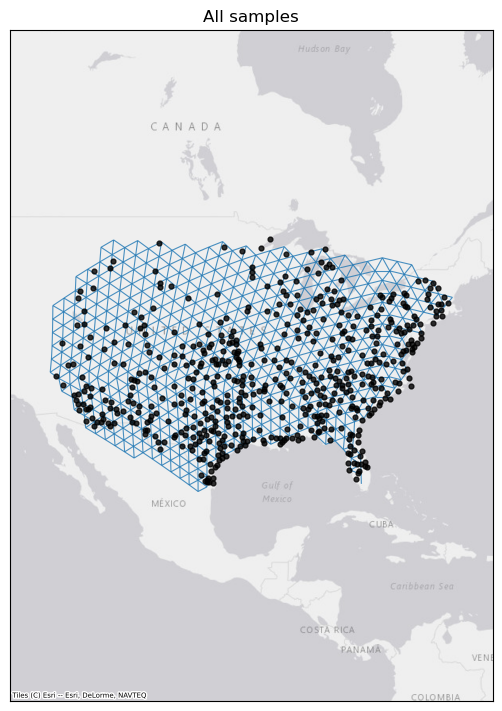

In [3]:
%%time
raster_paths = glob.glob('/Users/isaac/.cache/meadow/climate/bioclim/wc2.1/2.5m/bio/*.tif')

graphs, stats = build_species_graphs(
    sp_list,
    input_graph="EasternSnake.gml",
    support_decay_km=200,
    raster_paths=raster_paths,
    raster_fill_method="nearest",
)
_ = plot_samples(graphs)

In [4]:
%%time

model = train_model(
    graphs,
    epochs=1000,
    patience=100,
    min_delta=1e-5,
    lr=1e-2,
    edge_smoothing=0.05,
)

epoch   25 loss 0.003230 val 0.003714
epoch   50 loss 0.002636 val 0.003303
epoch   75 loss 0.002488 val 0.003294
epoch  100 loss 0.002449 val 0.003342
epoch  125 loss 0.002378 val 0.003335
early stop at epoch 144 val 0.003327 best 0.003299
Validation [EasternSnake_community]: model MSE=0.00329911, constant MSE=0.00546253, improvement=+39.6%
CPU times: user 8min 25s, sys: 1min 12s, total: 9min 38s
Wall time: 2min 10s


CPU times: user 367 ms, sys: 1.1 s, total: 1.47 s
Wall time: 244 ms


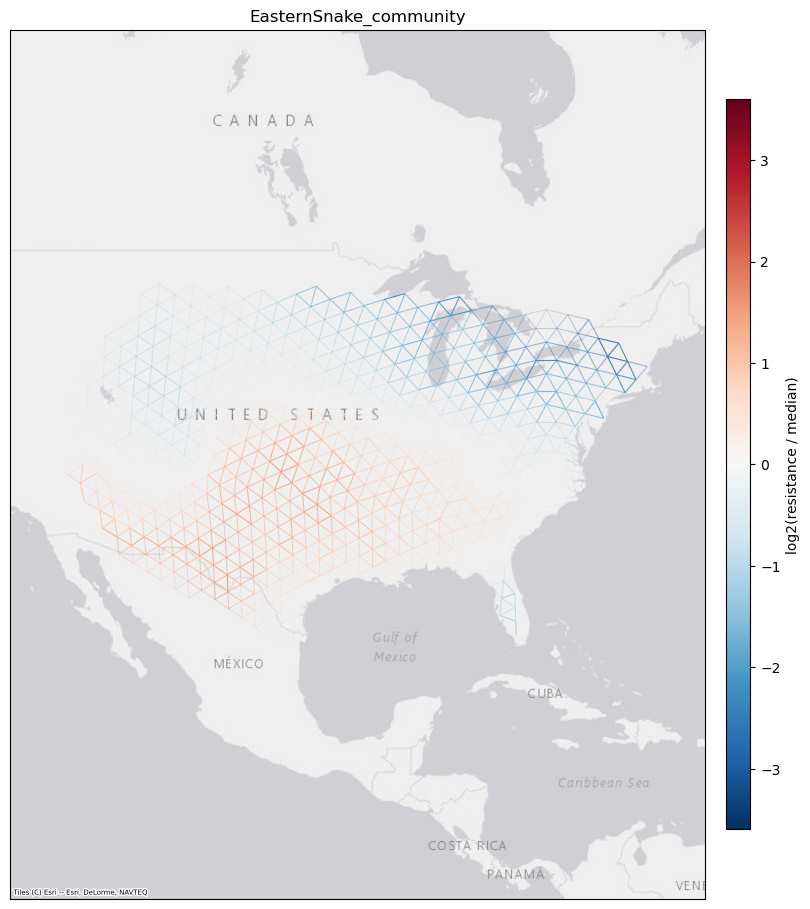

In [8]:
%%time
_ = plot_multi_edge_resistance(
    sp_list,
    graphs,
    model,
    #basemap=False,
    show_sites=False,
    explore=True,
    show_support_decay=True,
    support_decay_km=200,
    resistance_scale="log2_median",
)

In [7]:
%%time
from meadow.cv import choose_edge_smoothing_cv

res = choose_edge_smoothing_cv(graphs)

edge_smoothing=0.5 final refit run 60/60                                                                                
Best edge_smoothing=0.01 (CV MSE=0.00309536, improvement=+56.4%)
edge_smoothing CV summary:
  edge_smoothing    model_mse    model_mse_std    constant_mse    improvement_percent    edge_cv    edge_q90_q10
----------------  -----------  ---------------  --------------  ---------------------  ---------  --------------
           0.01    0.00309536      0.000859091      0.00710275                56.4203  0.682263          9.71101
           0.025   0.00312009      0.000932309      0.00710275                56.0722  0.602155          7.28838
           0.05    0.00313693      0.00100275       0.00710275                55.835   0.637507          7.45895
           0.075   0.00319072      0.000950424      0.00710275                55.0777  0.526589          5.30831
           0       0.00323747      0.000853279      0.00710275                54.4195  0.706374         11.95

In [ ]:
# Running both EasternSnakes CVs, run WNV next

# Try making fewer bigger clusters
# Check the min number of species per cluster and potentially have a cutoff
# Experiment with auto-grid construction

